# 23 — Consolidação das três estratégias e avaliação de margens

Compara o quantitativo institucional, a previsão do mesmo ExtraTrees e o planejamento combinado com +10, nas mesmas datas de cada ano. Em 2023, há aquecimento de 60 alvos anteriores: esta coorte difere da competição original.

Os pesos 25%/75% foram escolhidos após o diagnóstico de 2026. Esta etapa é exploratória. Margens usam resíduos da previsão combinada, sempre anteriores à sexta de emissão. A escolha ocorre na simulação de 2024, com conferência em 2025; a calibração de 2026 usa somente erros de 2023–2025. Não altera emissões congeladas.

O confronto prospectivo lê somente consumos aprovados, com fonte registrada; diferenças entre arquivos de coleta bloqueiam a pontuação. As figuras usam rótulos em português, sem títulos internos.


In [1]:
from pathlib import Path
import subprocess, sys, os
ROOT=Path(r"F:\PRODUTO_MESTRADO")
env=dict(os.environ, PYTHONIOENCODING="utf-8", PYTHONDONTWRITEBYTECODE="1")
for script in ["consolidar_tres_estrategias.py", "confrontar_emissoes_tres_estrategias.py"]:
    run=subprocess.run([sys.executable,str(ROOT/"scripts"/script)],cwd=ROOT,env=env,capture_output=True,text=True,encoding="utf-8")
    print(run.stdout)
    if run.returncode: raise RuntimeError(run.stderr)


 ano                     metodo  n_datas  MAE_refeicoes  WAPE_pct  vies_refeicoes  excesso_potencial  deficit_potencial  dias_deficit  perda_hipotetica_2a1
2023 Quantitativo institucional      120      16.600000 15.873775        0.966667             1054.0              938.0            51             24.416667
2024 Quantitativo institucional      122      39.819672 23.807890      -34.344262              334.0             4524.0           101             76.901639
2025 Quantitativo institucional      155      28.787097 20.801865      -20.193548              666.0             3796.0           122             53.277419
2026 Quantitativo institucional      123      26.211382 15.673311       15.430894             2561.0              663.0            48             31.601626
2023         Previsão do modelo      120      23.841667 22.798629        3.325000             1630.0             1231.0            64             34.100000
2024         Previsão do modelo      122      26.196721 15.66282

{
  "status": "aguardando_consumo_observado",
  "n_datas_aprovadas": 0,
  "previsoes_sha256_verificados": {
    "resultados\\validacao_prospectiva_20261005\\emissoes\\20261003_candidato_hibrido_v2\\previsoes_congeladas.csv": "fe5146a948631ab3a02c004d208ddd5bd4b15ba42c8cf8fe2bffb25a0744d818",
    "resultados\\experimento_treino_2026_20261003\\previsoes_semana_20261005_congeladas.csv": "e9d22b55f1ec26cd0484682fe568d432c9d379a4e86f390e1603cc1ff2e2d2d3"
  },
  "regra": "Confronto nas mesmas datas; candidato +10 continua primário. Treino apenas 2026 é teste separado, sem substituição posterior.",
  "setembro": "Permanece no confronto original; emissão posterior ao mês, avaliação retrospectiva"
}



,ano,metodo,n_datas,MAE_refeicoes,WAPE_pct,vies_refeicoes,excesso_potencial,deficit_potencial,dias_deficit,perda_hipotetica_2a1
0,2023,Quantitativo institucional,120,16.60,15.87,0.97,1054.0,938.0,51,24.42
1,2024,Quantitativo institucional,122,39.82,23.81,-34.34,334.0,4524.0,101,76.90
2,2025,Quantitativo institucional,155,28.79,20.80,-20.19,666.0,3796.0,122,53.28
3,2026,Quantitativo institucional,123,26.21,15.67,15.43,2561.0,663.0,48,31.60
4,2023,Previsão do modelo,120,23.84,22.80,3.32,1630.0,1231.0,64,34.10
5,2024,Previsão do modelo,122,26.20,15.66,-4.16,1344.0,1852.0,62,41.38
6,2025,Previsão do modelo,155,21.27,15.37,5.70,2090.0,1207.0,66,29.06
7,2026,Previsão do modelo,123,35.97,21.51,-14.28,1334.0,3090.0,86,61.09
8,2023,Planejamento combinado +10,120,18.79,17.97,11.94,1844.0,411.0,29,22.22
9,2024,Planejamento combinado +10,122,28.77,17.20,-16.43,753.0,2757.0,78,51.37


,ano,metodo,n_datas,MAE_refeicoes,WAPE_pct,vies_refeicoes,excesso_potencial,deficit_potencial,dias_deficit,perda_hipotetica_2a1
0,2023,Sem margem,120,15.69,15.01,1.94,1058.0,825.0,58,22.57
1,2023,Fixa +10,120,18.79,17.97,11.94,1844.0,411.0,29,22.22
2,2023,Quantil global,120,17.44,16.68,8.49,1556.0,537.0,36,21.92
3,2023,Quantil por dia,120,17.46,16.69,8.54,1560.0,535.0,35,21.92
4,2023,Quantil por dia e período,120,17.46,16.69,8.54,1560.0,535.0,35,21.92
5,2024,Sem margem,122,32.98,19.72,-26.43,400.0,3624.0,95,62.69
6,2024,Fixa +10,122,28.77,17.20,-16.43,753.0,2757.0,78,51.37
7,2024,Quantil global,122,30.20,18.05,-7.97,1356.0,2328.0,67,49.28
8,2024,Quantil por dia,122,29.82,17.83,-7.07,1388.0,2250.0,70,48.26
9,2024,Quantil por dia e período,122,29.67,17.74,-5.31,1486.0,2134.0,69,47.16


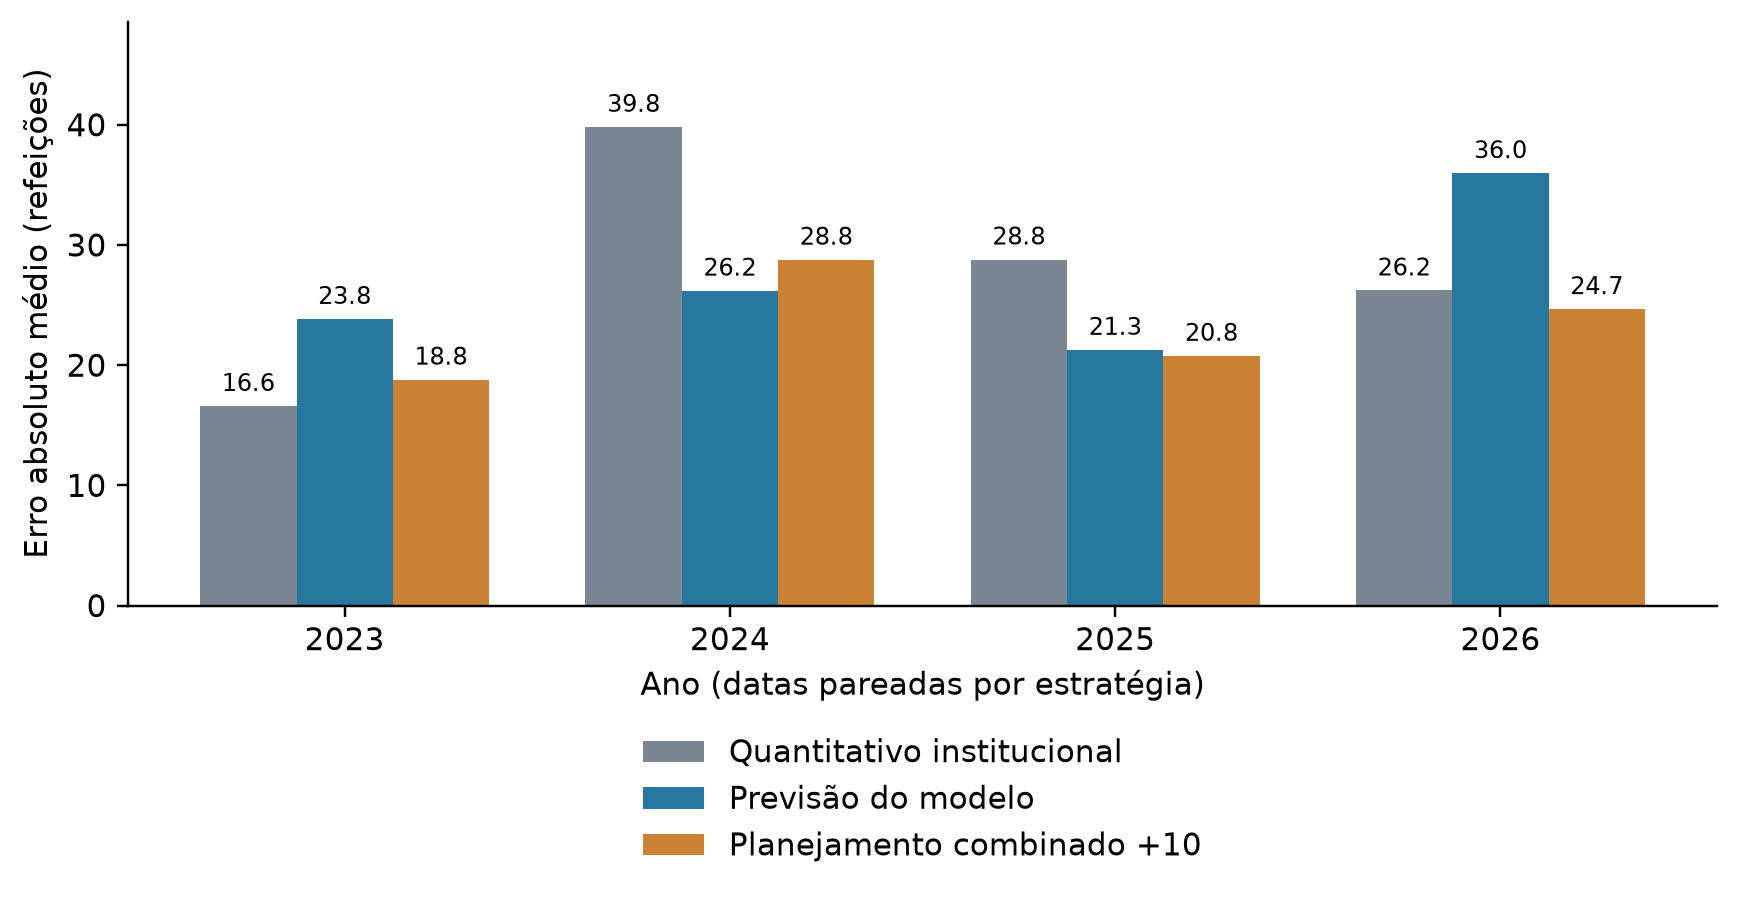

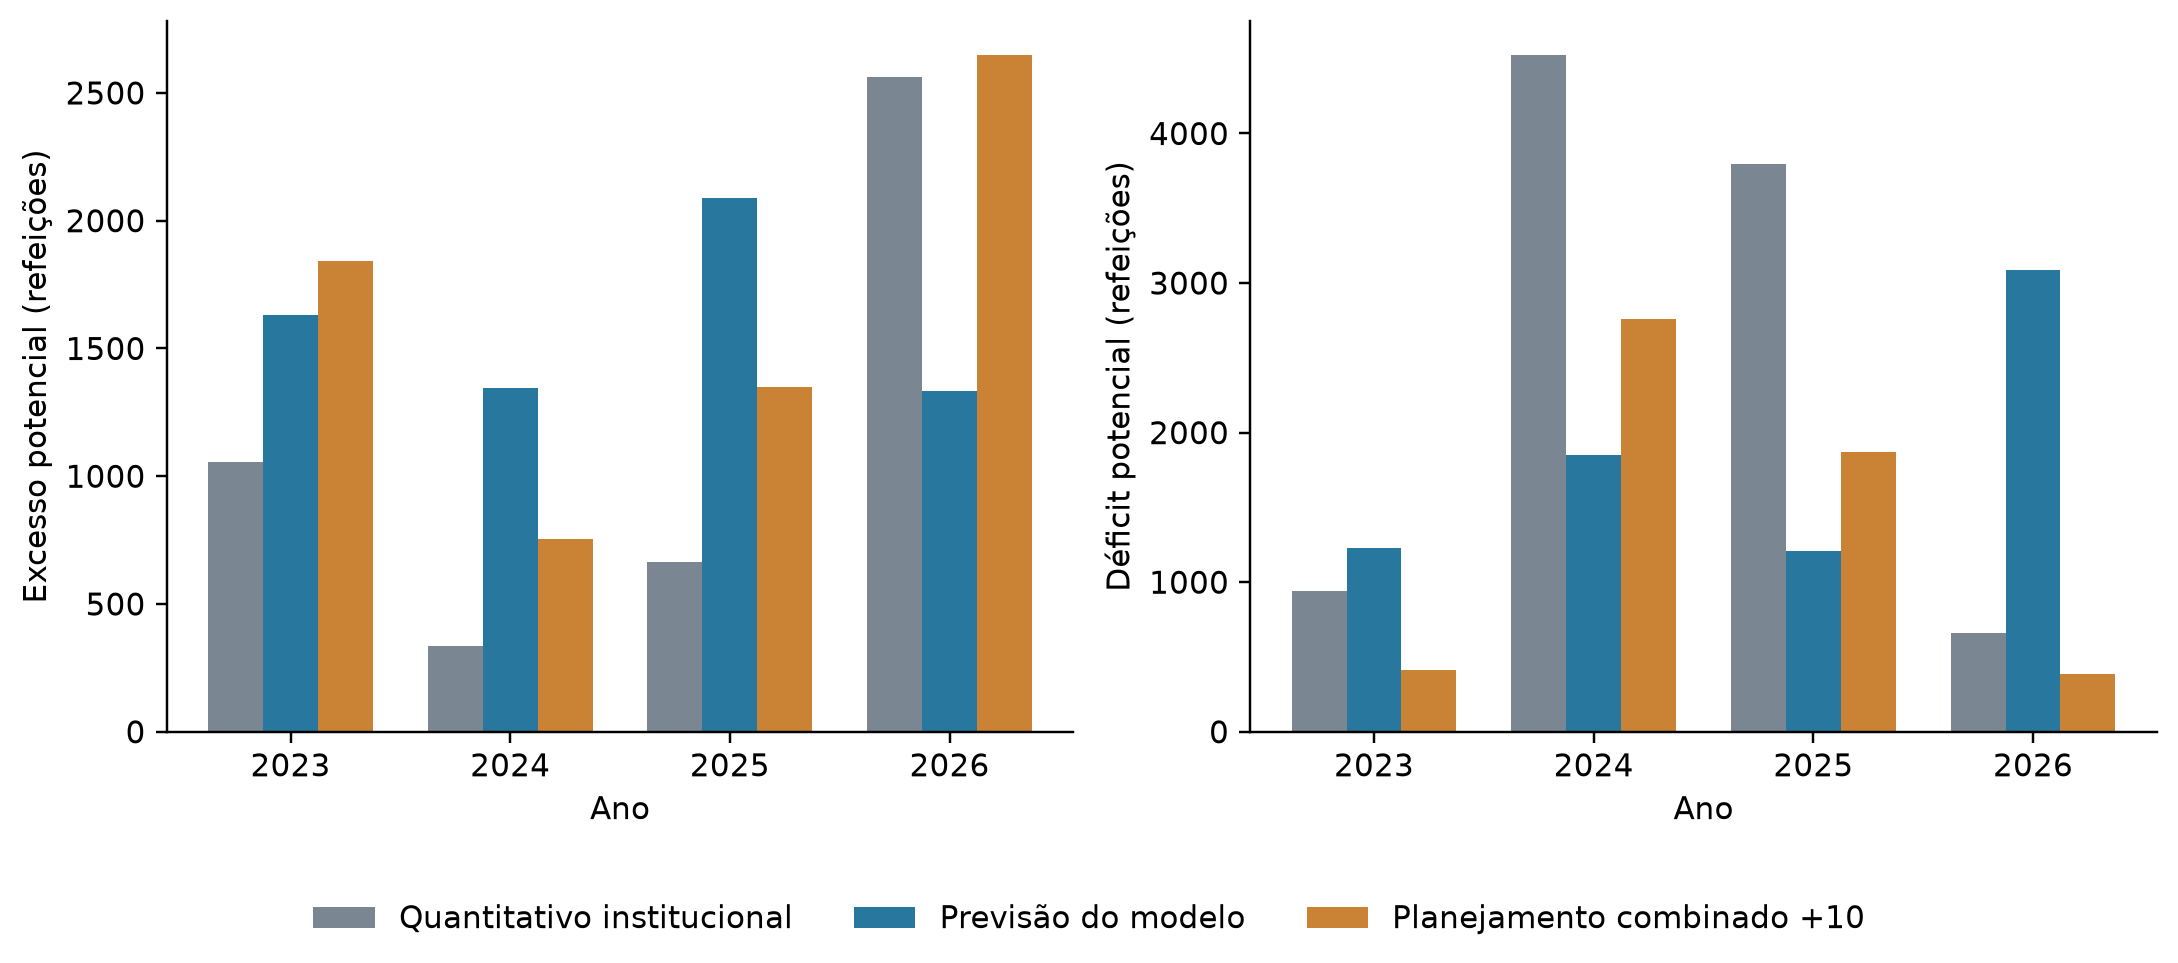

In [2]:
import pandas as pd
from IPython.display import display, Image
OUT=ROOT/"resultados/tres_estrategias_20261003"
display(pd.read_csv(OUT/"metricas_tres_estrategias.csv").round(2))
display(pd.read_csv(OUT/"metricas_margens.csv").round(2))
display(Image(filename=str(OUT/"figuras/erro_tres_estrategias.png")))
display(Image(filename=str(OUT/"figuras/excesso_deficit_tres_estrategias.png")))


## Interpretação

Reduzir o déficit pode aumentar o excesso e o erro médio. Uma margem mais detalhada precisa mostrar ganho em outras janelas antes de substituir a regra atual. A perda com peso 2:1 é uma hipótese de avaliação; não representa cobrança da empresa ou penalidade medida.

As emissões anteriores e os resultados originais continuam registrados. Cinco dias de confronto constituem uma avaliação inicial. A avaliação de utilidade com a gestão e a adoção operacional precisam de evidências próprias no percurso DSR.
